Name: Mia Parker

Github Username: emeliap-usc

ID: 1412-4907-44

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
import math
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

# 1.

## a)

In [ ]:
cols = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains", "burning_urethra", "bladder_inflammation", "nephritis"]

df = pd.read_csv("../data/diagnosis.data", encoding="utf-16", sep="\t", decimal=",", header=None, names=cols)

df[cols[1:]] = (df[cols[1:]] == "yes").astype(int)

In [3]:
df

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...
115,41.4,0,1,1,0,1,0,1
116,41.5,0,0,0,0,0,0,0
117,41.5,1,1,0,1,0,0,1
118,41.5,0,1,1,0,1,0,1


## b)

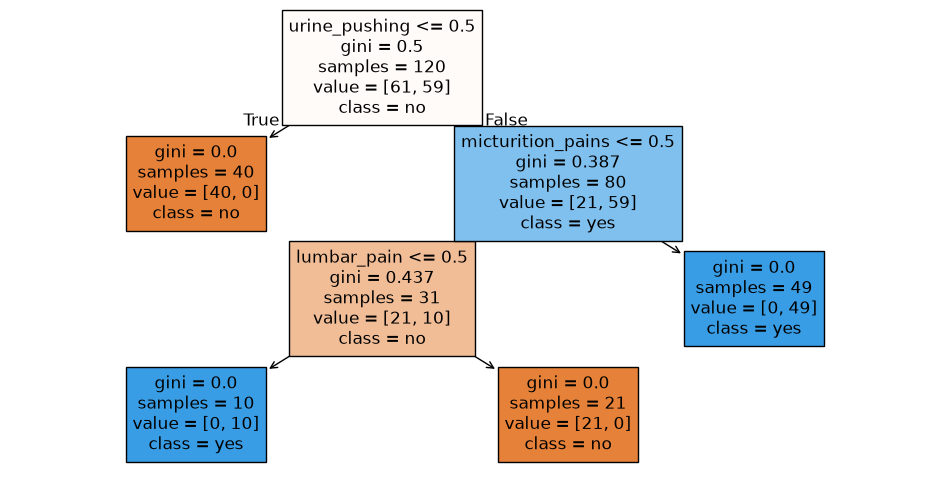

In [4]:
target = "bladder_inflammation"
x = df.drop(columns=["bladder_inflammation", "nephritis"])
y = df[target]
classes = ["no", "yes"]


tree = DecisionTreeClassifier(random_state=0).fit(x, y)
plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=x.columns, class_names=classes, filled=True)
plt.show()

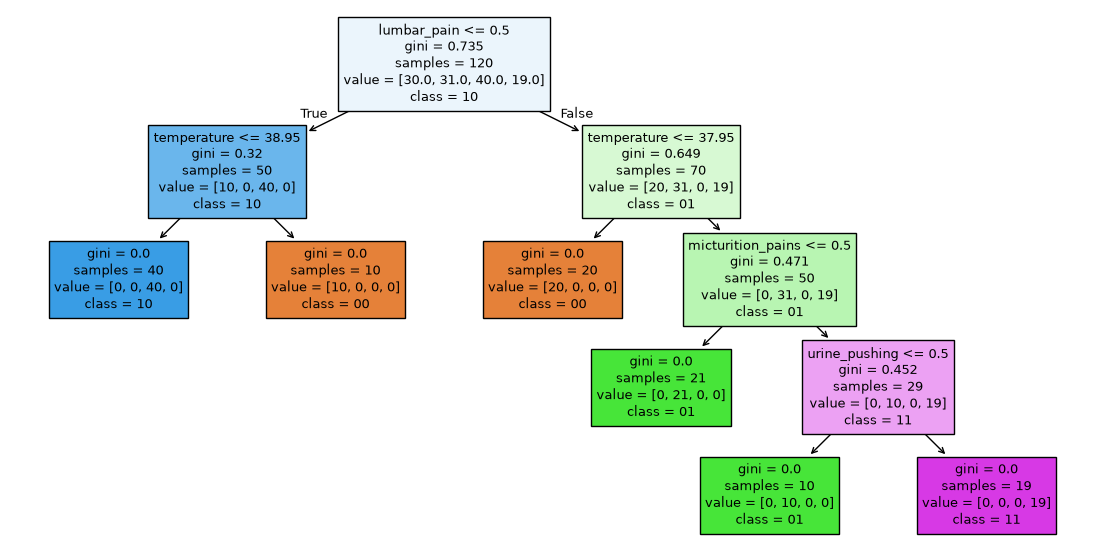

In [5]:
y_multi = df["bladder_inflammation"].astype(str) + df["nephritis"].astype(str)   # "00","01","10","11"
classes_multi = sorted(y_multi.unique())

tree_multi = DecisionTreeClassifier(random_state=0).fit(x, y_multi)
plt.figure(figsize=(14, 7))
plot_tree(tree_multi, feature_names=x.columns, class_names=classes_multi, filled=True)
plt.show()

In [6]:
print(export_text(tree_multi, feature_names=list(x.columns)))

|--- lumbar_pain <= 0.50
|   |--- temperature <= 38.95
|   |   |--- class: 10
|   |--- temperature >  38.95
|   |   |--- class: 00
|--- lumbar_pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: 00
|   |--- temperature >  37.95
|   |   |--- micturition_pains <= 0.50
|   |   |   |--- class: 01
|   |   |--- micturition_pains >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: 01
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: 11



IF lumbar_pain <= 0.50 AND temperature <= 38.95 THEN class = 10
IF lumbar_pain <= 0.50 AND temperature > 38.95 THEN class = 00
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN class = 00
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains <= 0.50 THEN class = 01
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN class = 01
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN class = 11

In [7]:
alphas = tree_multi.cost_complexity_pruning_path(x, y_multi).ccp_alphas

rows = []
for a in alphas:
    t = DecisionTreeClassifier(ccp_alpha=a, random_state=0).fit(x, y_multi)
    s = cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=0), x, y_multi, cv=5)
    rows.append((a, t.get_n_leaves(), s.mean(), s.std() / np.sqrt(5)))

table = pd.DataFrame(rows, columns=["alpha", "leaves", "cv_acc", "se"])
print(table)

      alpha  leaves    cv_acc        se
0  0.000000       6  0.958333  0.028868
1  0.098167       4  0.775000  0.043461
2  0.133333       3  0.716667  0.046248
3  0.182000       2  0.600000  0.009129
4  0.222917       1  0.433333  0.054772


Cost-complexity pruning shows the full tree is already minimal. The unpruned tree has 6 leaves and a 5-fold CV accuracy of 95.8% (SE 0.029). Pruning to 4 leaves drops accuracy to 77.5%, to 3 leaves 71.7%, to 2 leaves 60.0%, and to 1 leaf 43.3%. No pruned tree is within one standard error of the best, so I keep alpha = 0. The 6 resulting rules use only four features and at most four conditions each, so the tree is already highly interpretable.

# 2.

In [ ]:
df = pd.read_csv('../data/communities.data', header=None, na_values="?")

## b)

In [9]:
df

,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.90,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1989,12,NaN,NaN,TempleTerracecity,10,0.01,0.40,0.10,0.87,0.12,...,0.01,0.28,0.05,NaN,NaN,NaN,NaN,0.00,NaN,0.09
1990,6,NaN,NaN,Seasidecity,10,0.05,0.96,0.46,0.28,0.83,...,0.02,0.37,0.20,NaN,NaN,NaN,NaN,0.00,NaN,0.45
1991,9,9.0,80070.0,Waterburytown,10,0.16,0.37,0.25,0.69,0.04,...,0.08,0.32,0.18,0.08,0.06,0.78,0.0,0.91,0.28,0.23
1992,25,17.0,72600.0,Walthamcity,10,0.08,0.51,0.06,0.87,0.22,...,0.03,0.38,0.33,0.02,0.02,0.79,0.0,0.22,0.18,0.19


In [10]:

df = df.drop(columns=[0, 1, 2, 3, 4])

X = df.iloc[:, :-1]
y = df.iloc[:, -1]

X_train, X_test = X.iloc[:1495], X.iloc[1495:]
y_train, y_test = y.iloc[:1495], y.iloc[1495:]


imputer = SimpleImputer(strategy="mean")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns)


## c)

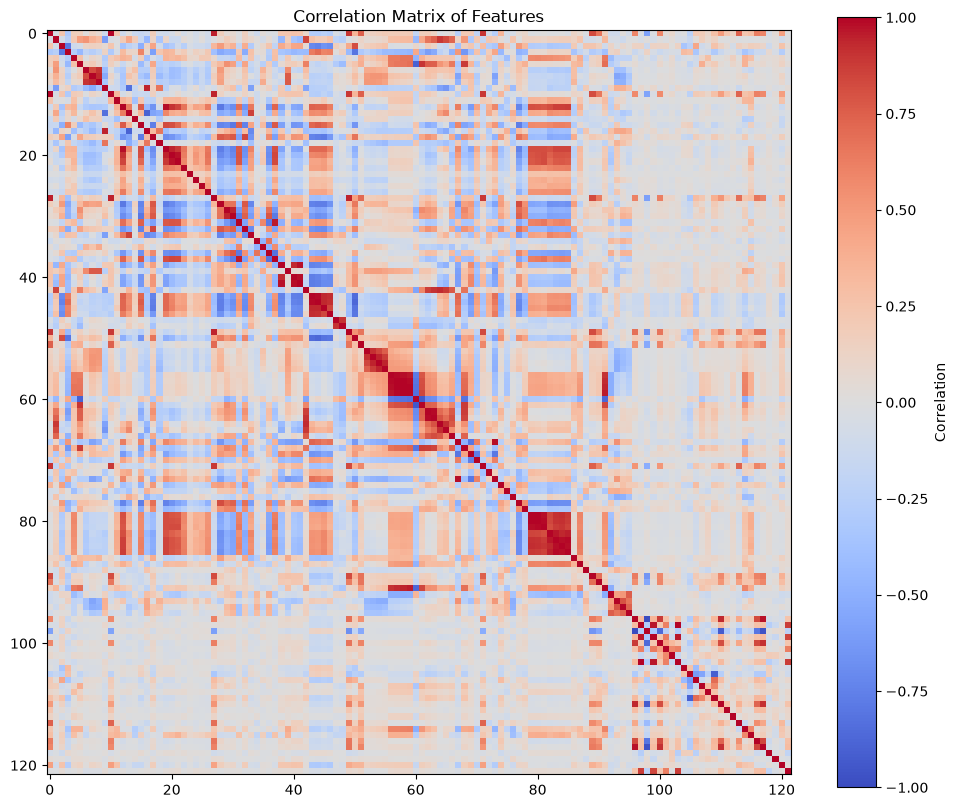

In [11]:
corr = X_train.corr()

plt.figure(figsize=(12, 10))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.title("Correlation Matrix of Features")
plt.show()

## d)

In [12]:
cv = X_train.std() / X_train.mean()
print(cv)

5      2.241105
6      0.355800
7      1.428885
8      0.330213
9      1.359100
         ...   
122    0.743487
123    0.115739
124    0.362989
125    2.552946
126    0.326026
Length: 122, dtype: float64


## e)

In [13]:
k = int(math.floor(math.sqrt(128)))                  # 11
top = cv.sort_values(ascending=False).head(k).index
print(list(top))

[95, 94, 54, 56, 125, 32, 5, 15, 76, 118, 10]


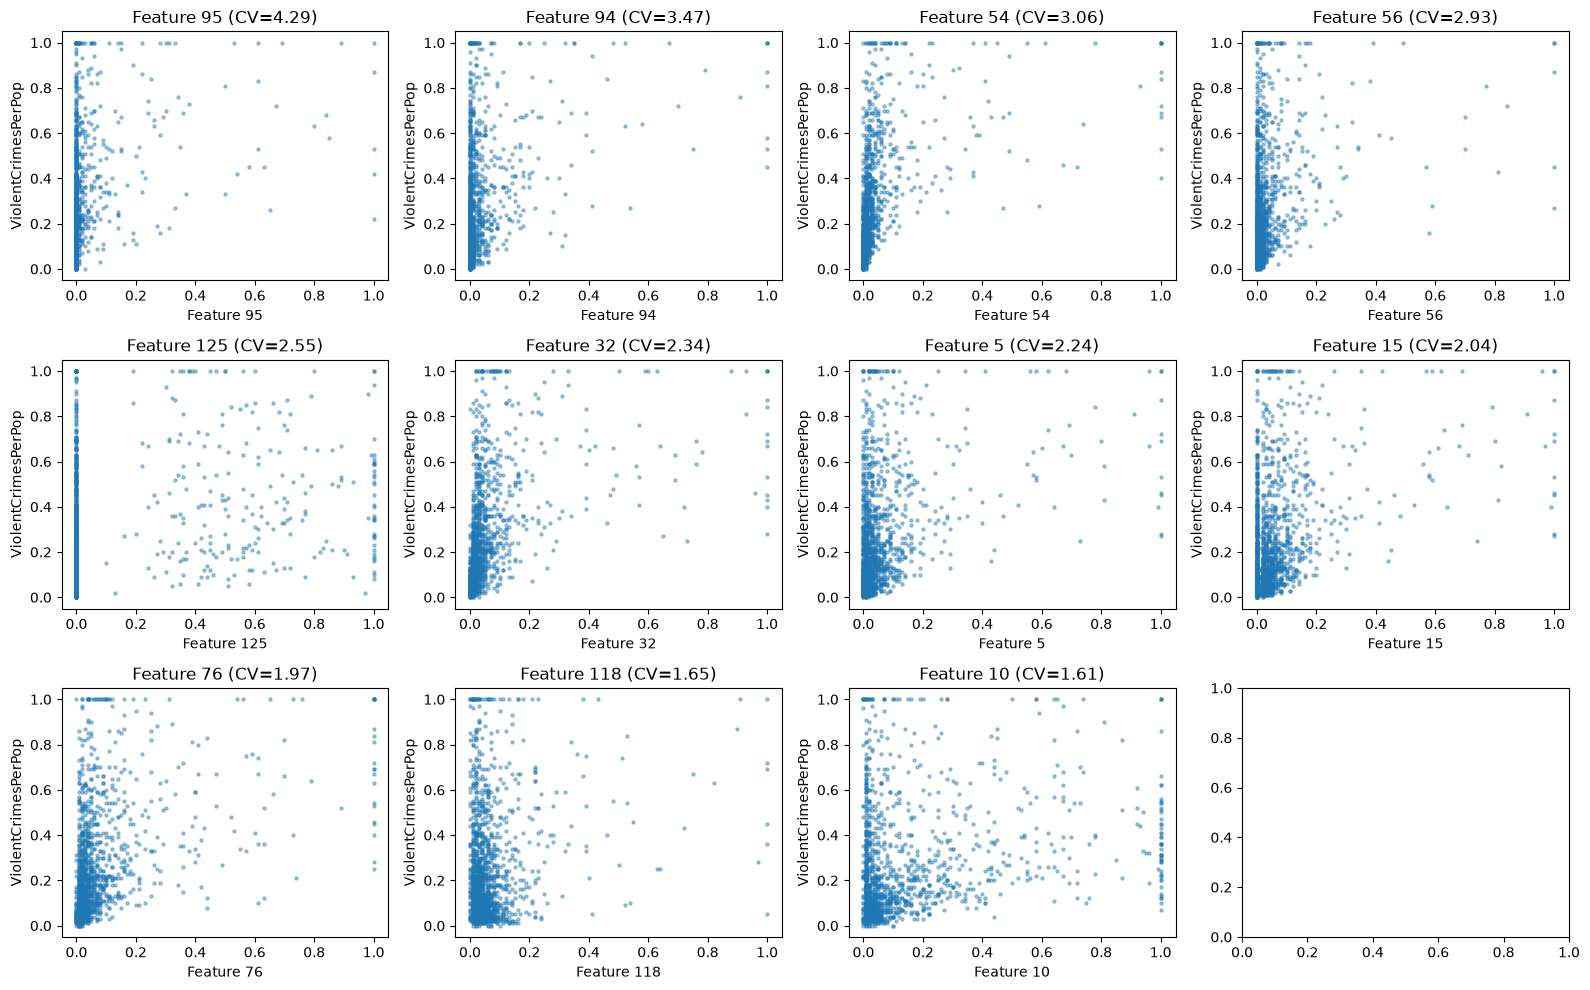

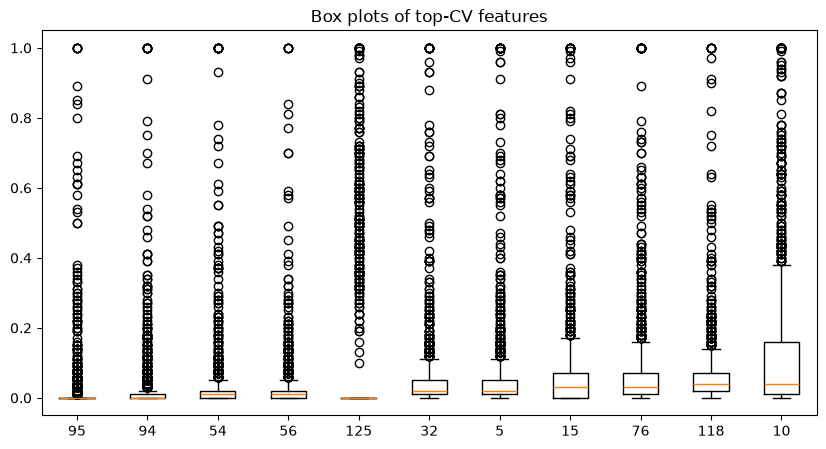

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, f in zip(axes.flat, top):
    ax.scatter(X_train[f], y_train, s=5, alpha=0.4)
    ax.set_title(f"Feature {f} (CV={cv[f]:.2f})")
    ax.set_xlabel(f"Feature {f}")
    ax.set_ylabel("ViolentCrimesPerPop")

plt.tight_layout()
plt.show()

# Box plots
plt.figure(figsize=(10, 5))
plt.boxplot([X_train[f] for f in top])
plt.xticks(range(1, k + 1), [str(f) for f in top])
plt.title("Box plots of top-CV features")
plt.show()

For the scatterplots, we see the majority of the points clustered around 0 for the feature, but overall see no relationship within the scatterplots. Within our boxplots its a similar distribution, a high amount of data clustered around 0, with plenty of outliers scatterered between 0 and 1. With this data it is very difficult to see a relationship or significance because of the high amount of points, it is difficult to discern the true density.

## f)

In [15]:
model = LinearRegression().fit(X_train, y_train)

train_mse = mean_squared_error(y_train, model.predict(X_train))
test_mse = mean_squared_error(y_test, model.predict(X_test))

print("Test MSE: ", test_mse)

Test MSE:  0.01814197113553011


## g)

In [16]:
alphas = np.logspace(-3, 3, 50)
ridge = RidgeCV(alphas=alphas, cv=5).fit(X_train, y_train)

print("Best lambda:", ridge.alpha_)
print("Test MSE: ", mean_squared_error(y_test, ridge.predict(X_test)))

Best lambda: 2.023589647725158
Test MSE:  0.017619653431557764


## h)

In [17]:
alphas = np.logspace(-5, -1, 50)

lasso = LassoCV(alphas=alphas, cv=5, max_iter=100000).fit(X_train, y_train)

print("Best lambda:", lasso.alpha_)
print("Test MSE: ", mean_squared_error(y_test, lasso.predict(X_test)))
print("Selected variables:", list(X_train.columns[lasso.coef_ != 0]))

Best lambda: 0.00011513953993264469
Test MSE:  0.01776091760288167
Selected variables: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 104, 105, 107, 109, 111, 113, 115, 116, 117, 118, 119, 120, 123, 124, 125, 126]


In [18]:
scaler = StandardScaler().fit(X_train)
Xs_train = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns)
Xs_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

lasso_s = LassoCV(alphas=alphas, cv=5, max_iter=100000).fit(Xs_train, y_train)

print("Best lambda:", lasso_s.alpha_)
print("Test MSE: ", mean_squared_error(y_test, lasso_s.predict(Xs_test)))
print("Selected variables:", list(Xs_train.columns[lasso_s.coef_ != 0]))

Best lambda: 0.0007543120063354615
Test MSE:  0.017808018828212174
Selected variables: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 58, 60, 64, 66, 68, 69, 72, 73, 74, 76, 77, 79, 80, 81, 82, 83, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 110, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124]


Without standardization, LASSO has test MSE 0.01776, 75 variables selected. With standardization, test MSE is 0.01781, 73 variables selected, with 69 variables in common. The difference is negligible, since the features were already normalized to [0, 1]. The selected sets differ slightly because standardizing changes how strongly each coefficient is penalized.

## i)

In [19]:
pcr = make_pipeline(StandardScaler(), PCA(), LinearRegression())

grid = GridSearchCV(pcr, {"pca__n_components": range(1, 123)}, cv=5, scoring="neg_mean_squared_error").fit(X_train, y_train)

best = grid.best_estimator_
print("Best M:", grid.best_params_["pca__n_components"])
print("Test MSE: ", mean_squared_error(y_test, best.predict(X_test)))

Best M: 95
Test MSE:  0.018392931230387752


## j)

In [20]:
xgb = XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=0)

grid = GridSearchCV(xgb, {"reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]},
                    cv=5, scoring="neg_mean_squared_error").fit(X_train, y_train)

best = grid.best_estimator_
print("Best alpha:", grid.best_params_["reg_alpha"])
print("Train MSE:", mean_squared_error(y_train, best.predict(X_train)))
print("Test MSE:", mean_squared_error(y_test, best.predict(X_test)))

Best alpha: 0.1
Train MSE: 0.008255221346197453
Test MSE: 0.01624011900279696
